#  Making [APPLICATION YOU ARE INTERESTED IN] from Scratch
# 1. Overview
- In this course, you choose a target application you are interested in in early weeks and parallelize/optimize it during the course, by understanding
  - multicore parallelization
  - GPU parallelization
  - Single Instruction Multiple Data (SIMD) and other special instructions (e.g., matrix instruction)
  - Instructin Level Parallelism (ILP)
  - cache and locality
  - etc.
- More important goal is to _understand and analyze_ performance
  - where time is spent
  - what limits the performance you observe
- You work on the same problem as a team (do not stick too much on the target application you initially chose/proposed here)
- Your team (whom you work with) will be detrmined a few weeks later, based on your submission for this assignment, your interest in other submissions, where you work (classroom or not), natural language preference (English/Japanese), etc.
- Be aware that your submission to this assignment will be read by other students in this class
  - do not write secret information you cannot leak to students in this class
  - do not embarrass yourself by AI slop (AI-generated text not proofread by yourself at all)

# 2. Jupyter AI
* You can ask Jupyter AI when you need help
* Open [pd02_app.chat](pd02_app.chat) in this folder
* Choose `OpenCode` in Persona Chooser
* You can try several models, but `LiteLLM (taulec)/GPT-5.3 Codex (UTokyo Azure)` is recommended for now
* It is instructed to help you but not to give you answer directly to exercise problems; do not try to circumvent it

# 3. AI use in this assignment
- You are allowed to use Jupyter AI for this assignment to, for example, 
  - ask interesting problem/algorithm in your interested area
  - generate a baseline serial code for it
  - generate an explanation about the generated code
- So, I am not expecting you to do much coding work or much reading
- In this assignment, feel free to let AI do heavy lifting and learn much from AI
- For transparency, use only Jupyter AI in this environment

# 4. So what you should do?
- You are instead expected to find an _interesting/realistic_ problem with which you can learn how parallel processing are applied to real problems
- Such problems might require too much work to code from scratch by yourself; you are therefore free to take advantage of AI for it rather than finish a tiny example by yourself
- You have to build and run the code by yourself on Miyabi
- The execution time should be easily configured with command line parameters or compile time macros (e.g., -DX=1024), so that the serial baseline code finishes in a reasonable amount of time (e.g., a few minutes) and should be scaled for parallel execution later
- It should produce some _meaningful_ and _verifiable_ results (results you can at least informally confirm correctness of)
- Obviously, you also have to make sure that the problem has ample _parallelism_ (solvable in parallel); exact speed up can be unknown at this point, of course, but you cannot choose an aribrary problem without any idea how to speed it up with parallel execution

- Above considerations may force you to change the problem setting or goals along the way; be prepared for it and start early
- For example, you obviously cannot finish an LLM pre-training with billion parameters that can speak fluent English within a few minutes
- Instead of immediately giving up LLM, consider lowering your goal to, for example, an LLM with much smaller vocaburary and much less ambitious goal regarding smartness; you don't have to abandon LLM

- This kind of exploration is what you are supposed to spend time on in this exercise

# 5. What you need to submit and how
## 5-1. Code and text
- `code/*.cc`, `code/*.cpp`, `code/*.h` etc. : A self-contained baseline code written in C++ that does _not require any external code_; it should compile without linking any external library besides ones automatically linked by the standard compiler
- [code/problem.md](code/problem.md) : a self-contained description of the problem that does not require much background knowledge to understand and a self-contained description of the baseline code (how it solves the problem); an almost empty template is already there; you can edit this file directly in Jupyter using text editor, edit it with your favorite editor if your editor supports editing remote files, or edit it locally and upload it to `code/` directory
- Make sure you fill cells below appropriately and the directory contains all and only files you need to submit (remove unnecessary files)
- Then just submit this assignment from Jupyter, which submits all files under this directory

- the following cell should succeed


In [2]:
%%bash
ls -l code/problem.md

-rw-r--r--+ 1 t81036 gt81 3142 Oct 30 20:07 code/problem.md


- the following cell should succeed and show filename(s) of your code


In [3]:
%%bash
ls -l code

total 1204
-rw-rw----+ 1 t81036 t81036 372963 Oct 30 19:01 image.png
-rw-rw----+ 1 t81036 gt81   786447 Oct 30 19:00 image.ppm
-rwxrwx---+ 1 t81036 t81036  26288 Oct 30 18:59 pathtracer
-rw-r-----+ 1 t81036 t81036  13582 Oct 30 19:02 pathtracer.cc
-rw-r--r--+ 1 t81036 gt81     3142 Oct 30 20:07 problem.md
-rw-r-----+ 1 t81036 t81036  12301 Oct 29 18:39 test.ppm


- add the command line to compile the code to the following cell and confirm it succeeds


In [4]:
%%bash
cd code
module purge && module load nvidia/25.9 cuda/12.9 && PATH=/work/gt81/share/env/llvm/bin:$PATH

clang++ -O3 -Wall -std=c++17 pathtracer.cc -o pathtracer


pathtracer.cc:40:6: warning: unused function 'operator*' [-Wunused-function]
   40 | Vec3 operator*(double s, const Vec3& v) { return v * s; }
      |      ^~~~~~~~
1 warning generated.


- add the command line to run the compiled program to the following cell and confirm it succeeds


In [5]:
%load_ext miyabi

In [9]:
%%sub
cd code

./pathtracer --width 512 --height 512 --spp 1024 --max-depth 10 --seed 42 --output image.ppm


Miyabi scheduled stop time: 2026/11/25(Wed) 09:00:00 (Remain: 8days 15:09:19)

JOB_ID            JOB_NAME   STATUS    PROJECT    QUEUE           START_DATE       ELAPSE        TOKEN NODE MIG
3930682           cd         RUNNING   gt81       lecture-mig     --:--:--         --:--:--          -    1   1
=== JOB STARTED ===


render_ms 94419.791
checksum 245216.4889376364
output image.ppm


## 5-2. Image files
* When appropriate (e.g., graphics application), let your app generate an image as a result 
* `ppm` is a very straightforward format you can easily generate from your app
* `convert` command can then convert it into `png`. e.g., 
```
convert a.ppm a.png
```

* add command line(s) to convert the generated image file into png


In [7]:
%%bash
cd code
convert image.ppm image.png


* uncomment the `Image` line and modify the filename below to display the image


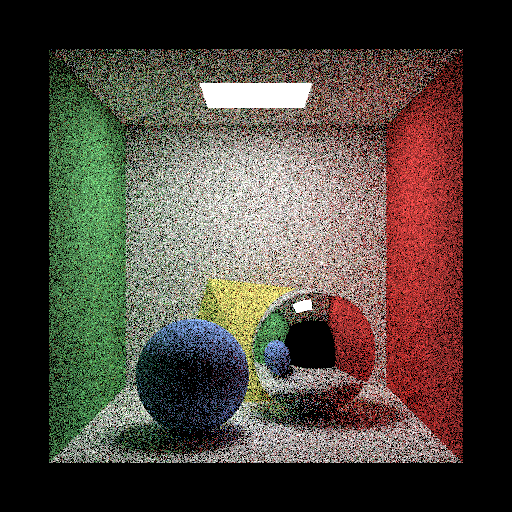

In [8]:
from IPython.display import Image, display

display(Image("code/image.png"))

# 6. A few hints about possible applications (just for a source of inspirations)
- LLM training from scratch
- LLM inferance from scratch
- Diffusion from scratch
- Ray-tracing from scratch
- Navie-Stokes from scratch
- Schrödinger equations from scratch
- Integer prime factorization from scratch
- Genome-indexing from scratch
- ...

